# Exercício 4 · Outliers
**Ciência de Dados — Preparação dos Dados (CRISP-DM)**
**Aluno(a):** ____________________

**Base:** Diamonds (seaborn), cerca de 54 mil diamantes com preço e medidas.

**Contexto:** valor extremo pode ser **erro** (alguém digitou errado) ou **caso raro, porém real** (um diamante enorme). O objetivo é separar uma coisa da outra antes de decidir o tratamento.

| Coluna | Significado |
|---|---|
| `carat` | peso em quilates (1 quilate = 0,2 g) |
| `depth` | altura total em % do diâmetro médio |
| `table` | largura da face de cima em % do diâmetro |
| `price` | preço em dólares |
| `x`, `y`, `z` | comprimento, largura e altura em milímetros |

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.width = 150
sns.set_style('whitegrid')

In [2]:
# CARREGAMENTO DOS DADOS
df = sns.load_dataset('diamonds')
print(df.shape)
df.head()

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75


In [3]:
# ESTATÍSTICAS DESCRITIVAS E VALORES IMPOSSÍVEIS
numericas = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
df[numericas].describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
carat,"53,940.00",0.80,0.47,0.20,0.24,0.70,2.18,5.01
depth,"53,940.00",61.75,1.43,43.00,57.90,61.80,65.60,79.00
table,"53,940.00",57.46,2.23,43.00,53.00,57.00,64.00,95.00
price,"53,940.00","3,932.80","3,989.44",326.00,429.00,"2,401.00","17,378.22","18,823.00"
x,"53,940.00",5.73,1.12,0.00,4.02,5.70,8.36,10.74
y,"53,940.00",5.73,1.14,0.00,4.04,5.71,8.34,58.90
z,"53,940.00",3.54,0.71,0.00,2.48,3.53,5.15,31.80


In [4]:
# Checagens físicas simples: o que não pode existir em um diamante?
checagens = {
    'alguma dimensão (x, y ou z) = 0 mm': (df[['x', 'y', 'z']] <= 0).any(axis=1),
    'as três dimensões = 0 mm': (df[['x', 'y', 'z']] <= 0).all(axis=1),
    'largura (y) acima de 20 mm': df['y'] > 20,
    'altura (z) acima de 20 mm': df['z'] > 20,
    'peso ou preço <= 0': (df['carat'] <= 0) | (df['price'] <= 0),
}
display(pd.Series({k: v.sum() for k, v in checagens.items()}, name='diamantes').to_frame())

print('Diamantes com dimensão gigante:')
df[(df['y'] > 20) | (df['z'] > 20)][['carat', 'depth', 'price', 'x', 'y', 'z']]

,diamantes
"alguma dimensão (x, y ou z) = 0 mm",20
as três dimensões = 0 mm,7
largura (y) acima de 20 mm,2
altura (z) acima de 20 mm,1
peso ou preço <= 0,0


Diamantes com dimensão gigante:


,carat,depth,price,x,y,z
24067,2.00,58.90,12210,8.09,58.90,8.06
48410,0.51,61.80,1970,5.12,5.15,31.80
49189,0.51,61.80,2075,5.15,31.80,5.12


**Valores impossíveis encontrados**
- **20 diamantes com alguma dimensão igual a 0 mm**, 7 deles com as três zeradas. Uma pedra com 0 mm não existe: é um dado que faltou e foi gravado como zero.
- **`y = 58,9 mm` e `z = 31,8 mm`:** o 99º percentil de `y` é cerca de 8,3 mm. Um diamante de 58,9 mm teria o tamanho de uma bola de golfe e pesaria centenas de quilates, mas este pesa 2. O de `z = 31,8` pesa 0,51 quilate e tem `depth` normal (61,8%): parece **vírgula no lugar errado** (3,18 mm faria sentido).
- Fora isso, peso e preço são sempre positivos.

Observação: a média e o máximo de `price` (3.933 e 18.823 dólares) mostram que a coluna é bem assimétrica, com cauda longa para os caros.

In [5]:
# DETECÇÃO — Z-SCORE
# z = (x - média) / desvio; outlier se |z| > 3
def outliers_zscore(base, cols, corte=3):
    z = (base[cols] - base[cols].mean()) / base[cols].std()
    return z.abs() > corte

flag_z = outliers_zscore(df, numericas)
flag_z.sum().rename('outliers (Z-score)').to_frame().T

,carat,depth,table,price,x,y,z
outliers (Z-score),439,685,336,1206,43,34,55


In [6]:
# DETECÇÃO — IQR
# outlier se estiver fora de [Q1 - 1,5·IQR ; Q3 + 1,5·IQR]
def limites_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

def outliers_iqr(base, cols, k=1.5):
    return pd.DataFrame({c: ~base[c].between(*limites_iqr(base[c], k)) for c in cols})

flag_iqr = outliers_iqr(df, numericas)

comparacao = pd.DataFrame({
    'Z-score': flag_z.sum(),
    'IQR': flag_iqr.sum(),
    'nos dois': (flag_z & flag_iqr).sum(),
    'limite superior Z (média + 3σ)': df[numericas].mean() + 3 * df[numericas].std(),
    'limite superior IQR': [limites_iqr(df[c])[1] for c in numericas],
})
display(comparacao)
print('Diamantes com outlier em pelo menos uma coluna -> Z-score:', flag_z.any(axis=1).sum(), '| IQR:', flag_iqr.any(axis=1).sum())

,Z-score,IQR,nos dois,limite superior Z (média + 3σ),limite superior IQR
carat,439,1889,439,2.22,2.00
depth,685,2545,685,66.05,64.75
table,336,605,336,64.16,63.50
price,1206,3540,1206,"15,901.12","11,885.62"
x,43,32,32,9.10,9.29
y,34,29,29,9.16,9.27
z,55,49,49,5.66,5.73


Diamantes com outlier em pelo menos uma coluna -> Z-score: 2350 | IQR: 6416


**Comparando os dois métodos**
- O **IQR aponta bem mais outliers** em `carat`, `depth`, `table` e `price` (ex.: `price` 3.540 contra 1.206). O motivo aparece nos limites: para `price`, o Z-score só considera estranho acima de cerca de 15.900 dólares, enquanto o IQR corta em cerca de 11.900. Em uma coluna assimétrica, a própria cauda aumenta a média e o desvio e "afrouxa" a régua do Z-score.
- Em `x`, `y` e `z`, que são mais simétricas, os dois métodos apontam quantidades parecidas (algumas dezenas).
- No total, **2.350** diamantes têm algum outlier pelo Z-score e **6.416** pelo IQR. Nenhum dos dois diz se o ponto é erro ou raridade: isso precisa de outro critério.

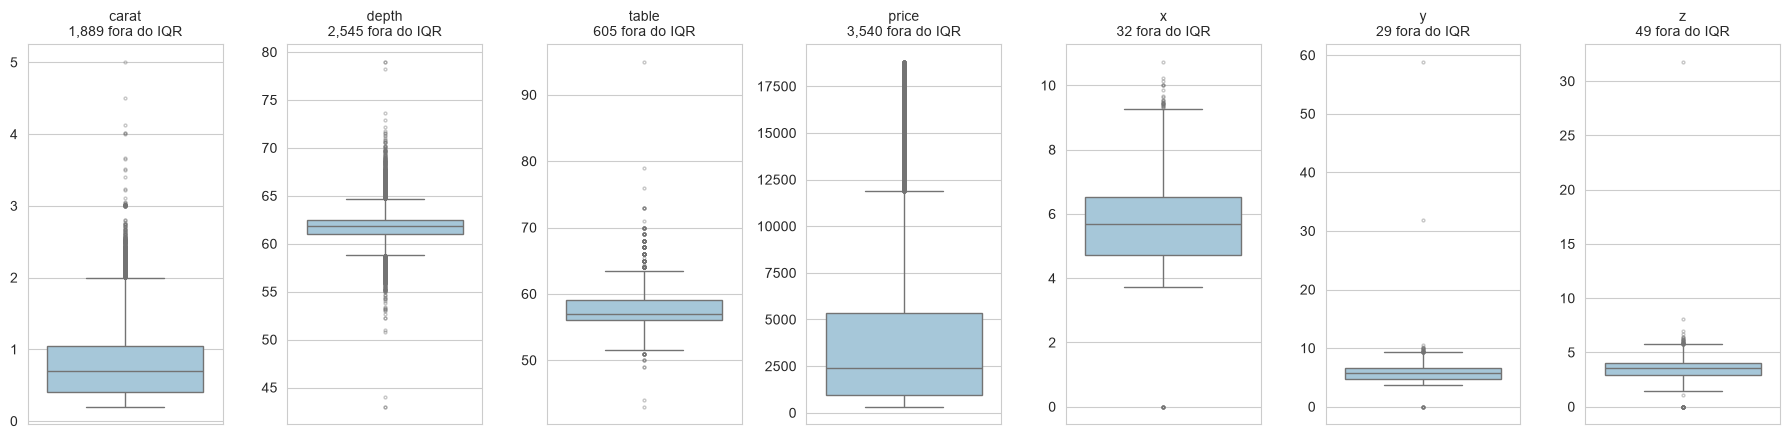

In [7]:
# VISUALIZAÇÕES — boxplots
fig, axes = plt.subplots(1, 7, figsize=(18, 4.5))
for ax, col in zip(axes, numericas):
    sns.boxplot(y=df[col], ax=ax, color='#9ecae1', flierprops={'markersize': 2, 'alpha': 0.4})
    ax.set_title(f'{col}\n{flag_iqr[col].sum():,} fora do IQR', fontsize=10)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

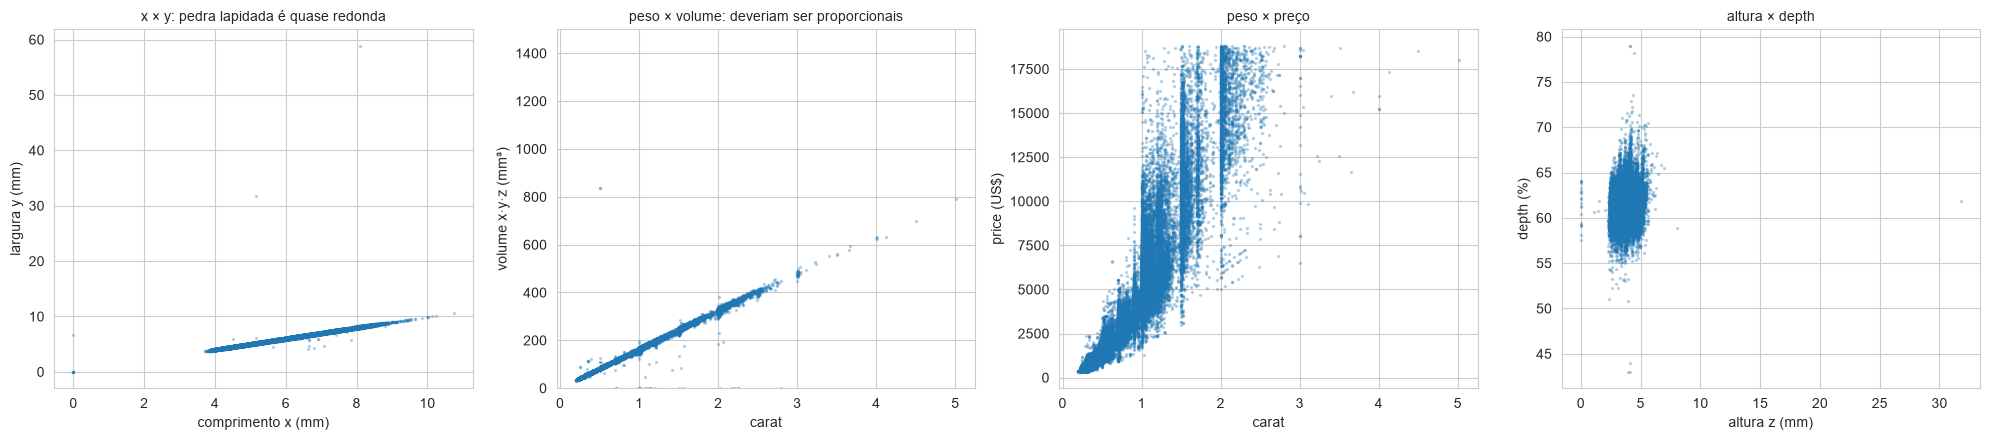

In [8]:
# VISUALIZAÇÕES — dispersão entre colunas que deveriam andar juntas
volume = df['x'] * df['y'] * df['z']
pares = [
    (df['x'], df['y'], 'comprimento x (mm)', 'largura y (mm)', 'x × y: pedra lapidada é quase redonda'),
    (df['carat'], volume, 'carat', 'volume x·y·z (mm³)', 'peso × volume: deveriam ser proporcionais'),
    (df['carat'], df['price'], 'carat', 'price (US$)', 'peso × preço'),
    (df['z'], df['depth'], 'altura z (mm)', 'depth (%)', 'altura × depth'),
]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (a, b, xl, yl, titulo) in zip(axes, pares):
    ax.scatter(a, b, s=2, alpha=0.25)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(titulo, fontsize=10)
axes[1].set_ylim(0, 1500)
plt.tight_layout()
plt.show()

**O que os gráficos mostram**
- Nos boxplots, `price` e `carat` têm uma "fila" longa de pontos acima do bigode: é a cauda de diamantes grandes e caros, que forma uma faixa contínua, sem saltos.
- Em `x × y` e `peso × volume`, quase todos os pontos ficam numa **linha fina**. Os pontos que fogem dela (dimensões zeradas, `y = 58,9`, `z = 31,8`) são impossíveis fisicamente.
- Em `peso × preço`, os diamantes mais pesados **continuam a tendência** dos demais: preço sobe com o peso. Extremo, mas coerente.
- Em `altura × depth` aparecem pontos com `z` muito baixo ou muito alto para o `depth` informado: mais um sinal de medida errada.

## Erro x valor extremo legítimo
**Critério: o diamante é fisicamente coerente?** Diamante tem densidade fixa (cerca de 3,5 g/cm³). Então **o peso precisa bater com o tamanho**. Criei a variável `densidade_aparente` = quilates por 1.000 mm³ da "caixa" x·y·z. Se as medidas estiverem certas, ela é praticamente constante; se alguma medida estiver errada, ela dispara ou despenca.

1. **Erro de registro:** dimensão igual a 0 **ou** densidade aparente a mais de 30% da mediana (para baixo ou para cima).
2. **Extremo legítimo:** fora do IQR em `carat` ou `price`, mas com medidas coerentes.

Por que 30%? A saída abaixo mostra que 97,8% dos diamantes ficam a menos de 5% da mediana e 99,8% a menos de 10%. Uma diferença de 30% está muito além de qualquer variação de lapidação ou de arredondamento de medida.

In [9]:
# ERRO x VALOR EXTREMO LEGÍTIMO
diam = df.copy()
dim_zero = (diam[['x', 'y', 'z']] <= 0).any(axis=1)
diam['densidade_aparente'] = np.where(dim_zero, np.nan, diam['carat'] / (diam['x'] * diam['y'] * diam['z']) * 1000)
mediana_dens = diam['densidade_aparente'].median()
desvio_rel = (diam['densidade_aparente'] / mediana_dens - 1).abs()

print(f'Densidade aparente mediana: {mediana_dens:.2f} quilates por 1.000 mm³')
print(pd.Series({f'a menos de {p:.0%} da mediana': (desvio_rel < p).mean() * 100 for p in [0.02, 0.05, 0.10]},
                name='% dos diamantes').round(2).to_string())

diam['erro_registro'] = dim_zero | (desvio_rel > 0.30)
diam['extremo_legitimo'] = (flag_iqr['carat'] | flag_iqr['price']) & ~diam['erro_registro']

print()
print(pd.Series({
    'erro: dimensão = 0': dim_zero.sum(),
    'erro: peso incompatível com o tamanho': (desvio_rel > 0.30).sum(),
    'TOTAL de erros de registro': diam['erro_registro'].sum(),
    'extremos legítimos (carat ou price)': diam['extremo_legitimo'].sum(),
}, name='diamantes').to_string())

Densidade aparente mediana: 6.12 quilates por 1.000 mm³
a menos de 2% da mediana    74.51
a menos de 5% da mediana    97.84
a menos de 10% da mediana   99.76

erro: dimensão = 0                         20
erro: peso incompatível com o tamanho      28
TOTAL de erros de registro                 48
extremos legítimos (carat ou price)      3743


In [10]:
# Os erros por incoerência, do mais baixo para o mais alto
cols_ver = ['carat', 'depth', 'price', 'x', 'y', 'z', 'densidade_aparente']
diam.loc[diam['erro_registro'] & ~dim_zero, cols_ver].sort_values('densidade_aparente')

,carat,depth,price,x,y,z,densidade_aparente
24067,2.00,58.90,12210,8.09,58.90,8.06,0.52
48410,0.51,61.80,1970,5.12,5.15,31.80,0.61
49189,0.51,61.80,2075,5.15,31.80,5.12,0.61
41019,0.25,59.00,1186,5.33,5.28,3.12,2.85
41020,0.25,58.80,1186,5.33,5.28,3.12,2.85
36652,0.35,62.40,949,5.67,5.64,3.53,3.10
36651,0.35,62.40,949,5.67,5.64,3.53,3.10
43425,0.35,65.90,1415,5.57,5.53,3.66,3.10
43424,0.35,65.90,1415,5.57,5.53,3.66,3.10
34282,0.39,61.20,468,4.51,6.02,4.44,3.24


Densidade aparente — legítimos: mediana 6.15 | máx. afastamento da mediana geral 13.8%


,carat,cut,color,clarity,price,x,y,z,densidade_aparente,erro_registro
25998,4.01,Premium,I,I1,15223,10.14,10.10,6.17,6.35,False
25999,4.01,Premium,J,I1,15223,10.02,9.94,6.24,6.45,False
27130,4.13,Fair,H,I1,17329,10.00,9.85,6.43,6.52,False
27415,5.01,Fair,J,I1,18018,10.74,10.54,6.98,6.34,False
27630,4.50,Fair,J,I1,18531,10.23,10.16,6.72,6.44,False


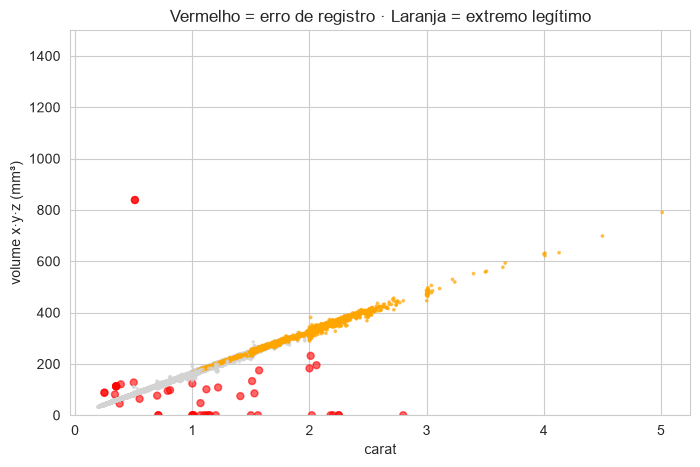

In [11]:
# Os extremos legítimos têm densidade normal? E os 5 diamantes acima de 4 quilates?
leg = diam[diam['extremo_legitimo']]
print(f"Densidade aparente — legítimos: mediana {leg['densidade_aparente'].median():.2f} | "
      f"máx. afastamento da mediana geral {(leg['densidade_aparente'] / mediana_dens - 1).abs().max() * 100:.1f}%")
display(diam[diam['carat'] > 4][['carat', 'cut', 'color', 'clarity', 'price', 'x', 'y', 'z', 'densidade_aparente', 'erro_registro']])

fig, ax = plt.subplots(figsize=(8, 5))
cores = np.select([diam['erro_registro'], diam['extremo_legitimo']], ['red', 'orange'], 'lightgray')
ax.scatter(diam['carat'], diam['x'] * diam['y'] * diam['z'], c=cores, s=np.where(cores == 'red', 25, 3), alpha=0.6)
ax.set_ylim(0, 1500); ax.set_xlabel('carat'); ax.set_ylabel('volume x·y·z (mm³)')
ax.set_title('Vermelho = erro de registro · Laranja = extremo legítimo')
plt.show()

**Classificação final**
- **48 erros de registro**: 20 com dimensão zerada e 28 com peso incompatível com o tamanho. Entre eles há padrões claros de digitação: `z` igual ao próprio quilate (ex.: 1,53 quilate com `z = 1,53 mm`, quando deveria ser perto de 4,5), vírgula fora do lugar (`z = 31,8`) e `y = 58,9`. Quase todos esses erros **não estão nas pontas** de `price` ou `carat`, e por isso nenhum método estatístico sozinho os encontraria.
- **Extremos legítimos**: 3.743 diamantes grandes ou caros, todos com densidade a no máximo 14% da mediana, ou seja, coerentes. Os 5 acima de 4 quilates são coerentes (medidas de 10 mm ou mais, preços altos) e foram classificados como **legítimos**.
- No gráfico, os pontos laranja continuam a linha de peso × volume; os vermelhos ficam fora dela.

## Tratamento
**Passo comum:** os 48 erros de registro são **removidos** em todas as estratégias, porque não são raridades, são medições erradas. As três estratégias abaixo tratam só os **extremos de `price`**, na base já sem erros.

| Estratégia | Como fiz | Por quê |
|---|---|---|
| Remoção | apagar diamantes com \|z\| > 3 em `price` | método do enunciado mais "conservador" (corta pouco) |
| Capping | limitar `price` aos percentis 1% e 99% (winsorização) | não depende de supor distribuição normal |
| Transformação | `log10(price)` e `sqrt(price)` | mantém todos os diamantes, só muda a escala |

In [12]:
# TRATAMENTO — REMOÇÃO / CAPPING / TRANSFORMAÇÃO
base = diam.loc[~diam['erro_registro'], df.columns].copy()
print(f'Base sem erros de registro: {len(base):,} diamantes (removidos {len(diam) - len(base)})')

# 1) Remoção pelo Z-score de price
z_price = (base['price'] - base['price'].mean()) / base['price'].std()
df_remocao = base[z_price.abs() <= 3].copy()

# 2) Capping nos percentis 1% e 99%
p01, p99 = base['price'].quantile([0.01, 0.99])
df_capping = base.copy()
df_capping['price'] = df_capping['price'].clip(p01, p99)

# 3) Transformação
df_transf = base.copy()
df_transf['price_log10'] = np.log10(df_transf['price'])
df_transf['price_sqrt'] = np.sqrt(df_transf['price'])

print(f'Remoção: {len(base) - len(df_remocao):,} diamantes apagados (preço acima de {base["price"].mean() + 3 * base["price"].std():,.0f})')
print(f'Capping: limites {p01:,.0f} e {p99:,.0f} | valores alterados: {(base["price"] != df_capping["price"]).sum():,}')
print(f'Transformação: {len(df_transf):,} diamantes, nenhum valor alterado na coluna original')

Base sem erros de registro: 53,892 diamantes (removidos 48)
Remoção: 1,204 diamantes apagados (preço acima de 15,890)
Capping: limites 429 e 17,365 | valores alterados: 1,068
Transformação: 53,892 diamantes, nenhum valor alterado na coluna original


In [13]:
# COMPARAÇÃO ENTRE AS ESTRATÉGIAS
def descreve(s):
    return pd.Series({'diamantes': len(s), 'média': s.mean(), 'mediana': s.median(), 'desvio': s.std(),
                      'mínimo': s.min(), 'máximo': s.max(), 'assimetria': s.skew()})

tabela = pd.DataFrame({
    'original': descreve(df['price']),
    'sem erros': descreve(base['price']),
    'remoção (|z|>3)': descreve(df_remocao['price']),
    'capping (p1–p99)': descreve(df_capping['price']),
    'log10(price)': descreve(df_transf['price_log10']),
    'sqrt(price)': descreve(df_transf['price_sqrt']),
}).T
display(tabela)

grandes = lambda b: (b['carat'] >= 2).sum()
print(f'Diamantes de 2 quilates ou mais: sem erros = {grandes(base):,} | após remoção = {grandes(df_remocao):,} '
      f'({(1 - grandes(df_remocao) / grandes(base)) * 100:.0f}% apagados)')

,diamantes,média,mediana,desvio,mínimo,máximo,assimetria
original,"53,940.00","3,932.80","2,401.00","3,989.44",326.00,"18,823.00",1.62
sem erros,"53,892.00","3,930.46","2,401.00","3,986.58",326.00,"18,823.00",1.62
remoção (|z|>3),"52,688.00","3,625.55","2,331.00","3,475.41",326.00,"15,889.00",1.45
capping (p1–p99),"53,892.00","3,923.62","2,401.00","3,961.26",429.00,"17,365.09",1.59
log10(price),"53,892.00",3.38,3.38,0.44,2.51,4.27,0.12
sqrt(price),"53,892.00",55.77,49.00,28.63,18.06,137.20,0.84


Diamantes de 2 quilates ou mais: sem erros = 2,144 | após remoção = 1,250 (42% apagados)


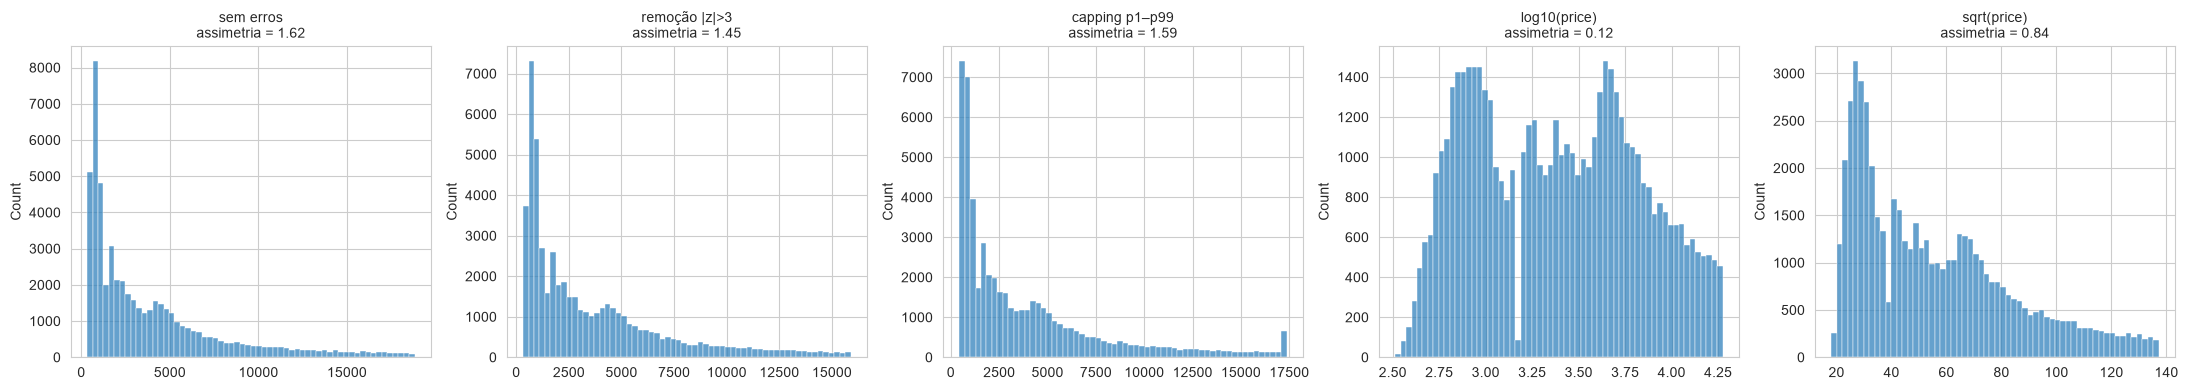

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
dist = [('sem erros', base['price']), ('remoção |z|>3', df_remocao['price']), ('capping p1–p99', df_capping['price']),
        ('log10(price)', df_transf['price_log10']), ('sqrt(price)', df_transf['price_sqrt'])]
for ax, (nome, s) in zip(axes, dist):
    sns.histplot(s, bins=60, ax=ax, color='#3182bd')
    ax.set_title(f'{nome}\nassimetria = {s.skew():.2f}', fontsize=10)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

**Impacto em `price`**
- **Remoção (|z| > 3):** apaga cerca de 1.200 diamantes (os acima de ~15.900 dólares). A média cai e a assimetria diminui, mas a perda está concentrada exatamente nas pedras grandes: **42% dos diamantes de 2 quilates ou mais desaparecem** (2.144 → 1.250). Uma análise de "quanto vale uma pedra grande" ficaria sem amostra.
- **Capping (p1–p99):** mantém todos os diamantes e só altera 1.068 preços (cerca de 2%). Média e desvio mudam pouco, mas surgem **dois picos artificiais** nos limites (muitos diamantes com exatamente o mesmo preço), e o preço dos mais caros deixa de ser o real.
- **Transformação:** não apaga nem altera nenhum dado. O **log10** deixa a distribuição praticamente simétrica (assimetria perto de 0,1, contra 1,6 no original); a **raiz quadrada** corrige só uma parte. É a opção que preserva a informação e ainda resolve o problema da assimetria, mas os resultados passam a ser lidos em escala log.

## Respostas às perguntas de reflexão

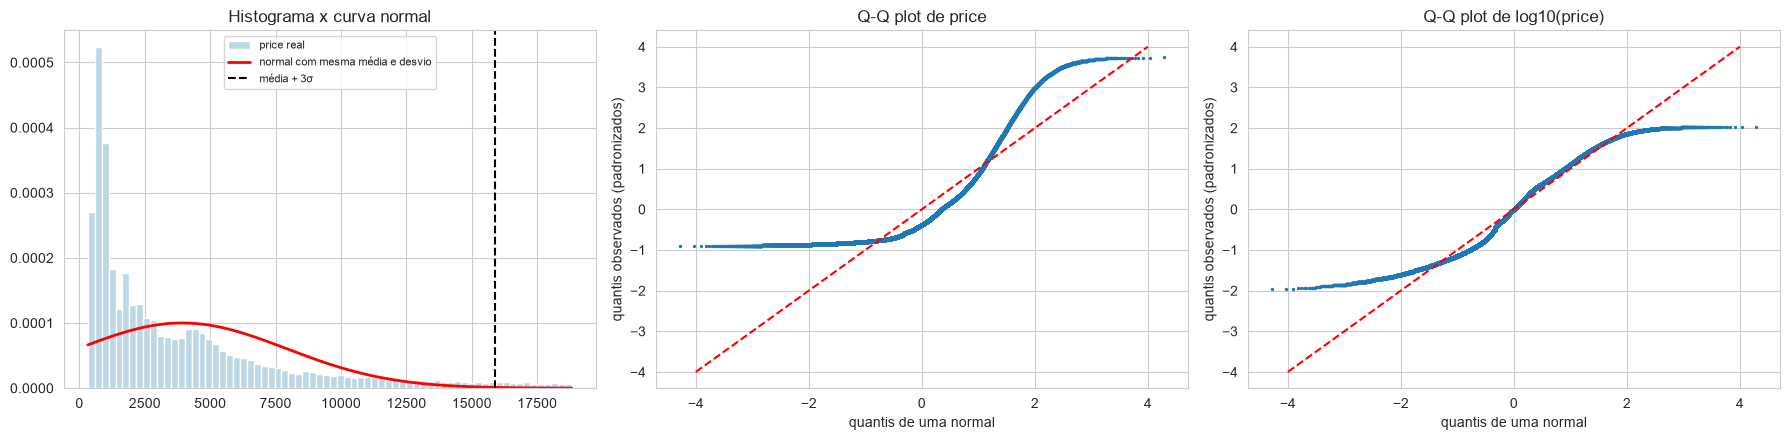

% de diamantes com |z| > 3 -> observado: 2.23% | esperado numa normal: 0.27%
% de diamantes com z < -3 (cauda esquerda): 0.00%


In [15]:
# RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO — o price segue uma distribuição normal?
preco = base['price']
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].hist(preco, bins=70, density=True, color='#bdd7e7', label='price real')
grade = np.linspace(preco.min(), preco.max(), 300)
axes[0].plot(grade, stats.norm.pdf(grade, preco.mean(), preco.std()), 'r', lw=2, label='normal com mesma média e desvio')
axes[0].axvline(preco.mean() + 3 * preco.std(), color='k', ls='--', label='média + 3σ')
axes[0].legend(fontsize=8); axes[0].set_title('Histograma x curva normal')

for ax, (nome, s) in zip(axes[1:], [('price', preco), ('log10(price)', np.log10(preco))]):
    ordenado = np.sort((s - s.mean()) / s.std())
    teorico = stats.norm.ppf((np.arange(1, len(ordenado) + 1) - 0.5) / len(ordenado))
    ax.scatter(teorico, ordenado, s=2)
    ax.plot([-4, 4], [-4, 4], 'r--')
    ax.set_xlabel('quantis de uma normal'); ax.set_ylabel('quantis observados (padronizados)')
    ax.set_title(f'Q-Q plot de {nome}')
plt.tight_layout()
plt.show()

print(f'% de diamantes com |z| > 3 -> observado: {(z_price.abs() > 3).mean() * 100:.2f}% | esperado numa normal: {2 * stats.norm.sf(3) * 100:.2f}%')
print(f'% de diamantes com z < -3 (cauda esquerda): {(z_price < -3).mean() * 100:.2f}%')

**1. O Z-score parte de qual suposição? Ela vale para `price`?**
O Z-score supõe que os dados seguem uma **distribuição normal** (em forma de sino e simétrica). Só nesse caso "estar a mais de 3 desvios da média" é raro de verdade: numa normal, isso acontece com apenas 0,27% dos dados, metade de cada lado. **Para `price` a suposição não vale.** O histograma mostra um pico nos diamantes baratos e uma cauda longa para a direita, bem diferente da curva vermelha; a curva normal chega até a prever preços negativos. No Q-Q plot, os pontos se afastam muito da reta nas pontas. E a prova numérica: há cerca de **2,2%** de diamantes com |z| > 3, oito vezes o esperado, **todos do lado direito** (nenhum com z < −3). Depois do `log10`, o Q-Q plot fica muito mais perto da reta, então para usar Z-score em preço o certo seria aplicá-lo no log.

**2. Um diamante de mais de 4 quilates é outlier a ser removido ou diamante raro? Como o objetivo muda a resposta?**
Pelos dados, é **raro e verdadeiro**: os 5 diamantes acima de 4 quilates têm medidas compatíveis com o peso (densidade aparente normal) e preços altos, como se espera. Não há motivo para chamá-los de erro. O que fazer com eles depende do objetivo:
- **modelo de preço para o estoque comum de uma loja**: posso excluí-los do treino *declarando* que o modelo vale até certo peso, ou usar log para que não dominem o ajuste;
- **estudo do mercado de pedras grandes ou avaliação de seguro**: eles são o centro da análise; tirar seria jogar fora o objeto de estudo;
- **auditoria de cadastro**: vale conferir um por um, por serem raros.
"Outlier" é uma propriedade estatística; "erro" é uma conclusão sobre o dado; "remover ou não" é uma decisão de negócio.

**3. Exemplo em que remover outliers esconderia o que o negócio quer descobrir.**
- **Segurança de rede:** um pico de acessos às 3h da manhã vindo de um único IP é exatamente o sinal de ataque. Limpar picos "estranhos" do log apagaria a invasão.
- **Controle de qualidade na indústria:** peças com medida fora da curva são justamente os defeitos que a fábrica quer contar e explicar.
- **Saúde pública:** um aumento repentino de casos numa cidade é o início de um surto; tratá-lo como outlier atrasaria o alerta.
- **Nesta base:** se uma joalheria quisesse precificar pedras grandes, a remoção pelo Z-score apagaria 42% dos diamantes de 2 quilates ou mais, como medido acima.